<a href="https://colab.research.google.com/github/CherryBlossom13/SLP-Iris/blob/main/Iris_RenyMedikawatiTaufiq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Reny Medikawati Taufiq
--------------------
Implementasi perhitungan forward pass, gradien, dan pembaruan parameter secara manual dengan NumPy, tanpa model bawaan scikit-learn/Keras.

Konfigurasi mengikuti template: setosa=0, versicolor=1, empat fitur, learning rate 0.1, bias dan bobot awal 0.5, lima epoch, sigmoid, prediksi 1 jika sigmoid > 0.5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Pembaca Excel memerlukan openpyxl.
FILE_PATH = Path("PMM-TemplateSLP.xlsx")
if not FILE_PATH.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Letakkan PMM-TemplateSLP.xlsx di folder notebook atau ubah FILE_PATH.")
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith(".xlsx")]
    if len(candidates) != 1:
        raise ValueError("Unggah tepat satu file Excel .xlsx.")
    FILE_PATH = Path(candidates[0])

raw = pd.read_excel(FILE_PATH, sheet_name=0, header=None).dropna(how="all")
if raw.shape[1] < 5:
    raise ValueError("Sheet pertama harus memiliki empat kolom fitur dan satu label.")
data = raw.iloc[:, :5].copy()
data.columns = ["X1", "X2", "X3", "X4", "kelas"]
data["kelas"] = data["kelas"].astype(str).str.strip()
label_map = {"Iris-setosa": 0, "Iris-versicolor": 1}
if not data["kelas"].isin(label_map).all():
    raise ValueError("Label sheet pertama harus Iris-setosa atau Iris-versicolor, tanpa header.")
X = data[["X1", "X2", "X3", "X4"]].apply(pd.to_numeric, errors="raise").to_numpy(dtype=float)
y = data["kelas"].map(label_map).to_numpy(dtype=int)
if not np.isfinite(X).all():
    raise ValueError("Fitur berisi nilai kosong/tidak valid.")
print("Jumlah data:", len(data))
print(data["kelas"].value_counts().to_string())
print(data.head().to_string(index=False))


Saving PMM-TemplateSLP.xlsx to PMM-TemplateSLP.xlsx
Jumlah data: 100
kelas
Iris-setosa        50
Iris-versicolor    50
 X1  X2  X3  X4       kelas
5.1 3.5 1.4 0.2 Iris-setosa
4.9 3.0 1.4 0.2 Iris-setosa
4.7 3.2 1.3 0.2 Iris-setosa
4.6 3.1 1.5 0.2 Iris-setosa
5.0 3.6 1.4 0.2 Iris-setosa


Pembagian data sesuai template
------------------------------
Ambil 40 data pertama setiap kelas untuk training, urutan training: 40 setosa kemudian 40 versicolor. Lalu 10 data terakhir setiap kelas untuk validation.  Data validation selalu sama pada seluruh epoch.

In [2]:
class_indices = [np.flatnonzero(y == label) for label in (0, 1)]
if any(len(idx) != 50 for idx in class_indices):
    raise ValueError("Template ini mengharapkan 50 data per kelas.")
train_idx = np.concatenate([idx[:40] for idx in class_indices])
val_idx = np.concatenate([idx[40:] for idx in class_indices])
assert len(set(train_idx) & set(val_idx)) == 0
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
print("Training:", X_train.shape, "Validation:", X_val.shape)

LEARNING_RATE = 0.1
EPOCHS = 5

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def evaluate(X_eval, y_eval, weights, bias):
    # Tidak ada pembaruan parameter dalam fungsi evaluasi.
    probabilities = sigmoid(X_eval @ weights + bias)
    predictions = (probabilities > 0.5).astype(int)
    loss = np.mean((probabilities - y_eval) ** 2)
    accuracy = np.mean(predictions == y_eval) * 100
    return float(loss), float(accuracy), probabilities, predictions


Training: (80, 4) Validation: (20, 4)


Training manual dan validasi setiap epoch
------------------------------

Untuk satu sampel: z = bias + jumlah(w × x), p = sigmoid(z), L = (p − y)².

Gradien bias = 2(p − y)p(1 − p); gradien bobot ke-j = gradien bias × x_j. Parameter baru = parameter lama − learning rate × gradien.

Training loss dan accuracy direkap dari prediksi sebelum pembaruan pada setiap sampel (sesuai baris spreadsheet). Validation loss dan accuracy dihitung memakai parameter setelah seluruh 80 pembaruan selesai.

In [3]:
weights = np.full(4, 0.5, dtype=float)
bias = 0.5
history, training_detail, validation_detail, parameter_history = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    epoch_losses, epoch_correct = [], []
    for sample_no, (x_i, target) in enumerate(zip(X_train, y_train), start=1):
        # Forward pass dengan parameter saat ini.
        z = float(np.dot(weights, x_i) + bias)
        p = float(sigmoid(z))
        prediction = int(p > 0.5)
        error = p - target
        squared_error = error ** 2

        # Turunan dihitung sebelum parameter mana pun diperbarui.
        grad_bias = 2.0 * error * p * (1.0 - p)
        grad_weights = grad_bias * x_i
        row = {"epoch": epoch, "sample": sample_no,
               "source_row": int(train_idx[sample_no-1] + 1),
               "target": int(target), "bias": bias, "z": z,
               "sigmoid": p, "prediction": prediction,
               "error": error, "squared_error": squared_error,
               "grad_bias": grad_bias}
        for j in range(4):
            row[f"X{j+1}"] = x_i[j]
            row[f"w{j+1}"] = weights[j]
            row[f"grad_w{j+1}"] = grad_weights[j]
        training_detail.append(row)
        epoch_losses.append(squared_error)
        epoch_correct.append(prediction == target)

        # SGD: satu pembaruan untuk setiap data, termasuk data terakhir.
        weights = weights - LEARNING_RATE * grad_weights
        bias = bias - LEARNING_RATE * grad_bias

    val_loss, val_acc, val_p, val_pred = evaluate(X_val, y_val, weights, bias)
    history.append({"Epoch": epoch,
                    "Training Loss": float(np.mean(epoch_losses)),
                    "Validation Loss": val_loss,
                    "Akurasi Training (%)": float(np.mean(epoch_correct) * 100),
                    "Akurasi Validasi (%)": val_acc})
    parameter_history.append({"epoch": epoch, "bias": bias,
                              **{f"w{j+1}": weights[j] for j in range(4)}})
    for k in range(len(y_val)):
        validation_detail.append({"epoch": epoch, "sample": k+1,
            "source_row": int(val_idx[k]+1), "target": int(y_val[k]),
            "sigmoid": float(val_p[k]), "prediction": int(val_pred[k]),
            "squared_error": float((val_p[k]-y_val[k])**2)})

metrics = pd.DataFrame(history)
print(metrics.to_string(index=False, float_format=lambda v: f"{v:.10f}"))
print("\nParameter akhir setiap epoch:")
print(pd.DataFrame(parameter_history).to_string(index=False))


 Epoch  Training Loss  Validation Loss  Akurasi Training (%)  Akurasi Validasi (%)
     1   0.4498886551     0.3289511566         52.5000000000         50.0000000000
     2   0.0374519142     0.2472893233         95.0000000000         50.0000000000
     3   0.0243721950     0.1758916407         97.5000000000         50.0000000000
     4   0.0173572017     0.1193813733         97.5000000000         85.0000000000
     5   0.0127401582     0.0815813694         98.7500000000        100.0000000000

Parameter akhir setiap epoch:
 epoch     bias        w1        w2       w3       w4
     1 0.380336 -0.019133  0.071447 0.524449 0.551140
     2 0.342472 -0.093195 -0.076158 0.707221 0.636439
     3 0.310418 -0.152266 -0.203786 0.865711 0.709340
     4 0.282274 -0.201860 -0.318152 1.002541 0.770788
     5 0.257720 -0.241802 -0.416903 1.122214 0.824059


Grafik accuracy dan grafik loss
-------------------------------
 Nilai diambil dari hasil training Python.

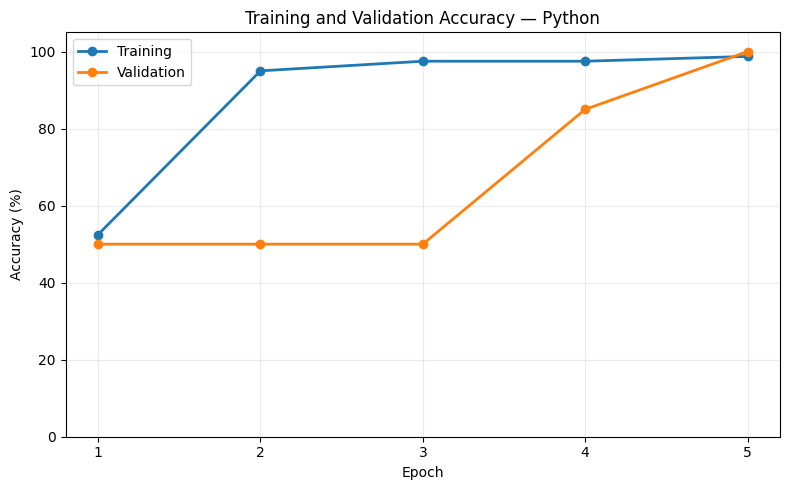

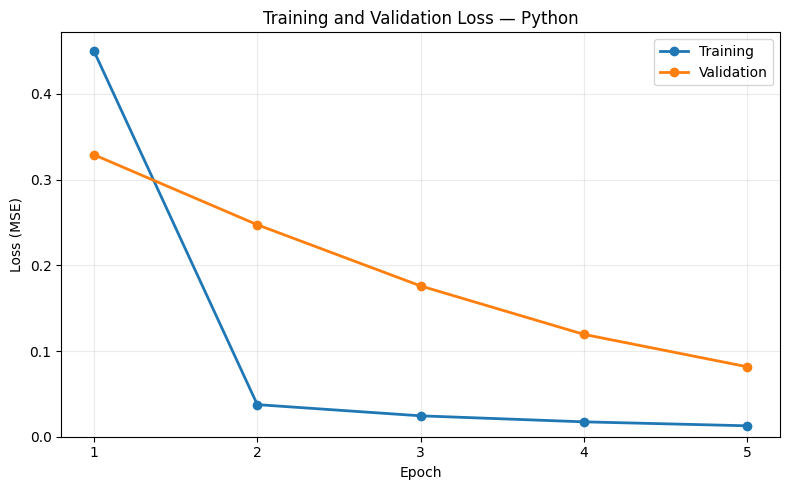

Hasil disimpan ke: /content/hasil_slp_manual


In [4]:
OUTPUT_DIR = Path("hasil_slp_manual")
OUTPUT_DIR.mkdir(exist_ok=True)
metrics.to_csv(OUTPUT_DIR / "metrics_per_epoch.csv", index=False)
pd.DataFrame(training_detail).to_csv(OUTPUT_DIR / "training_detail.csv", index=False)
pd.DataFrame(validation_detail).to_csv(OUTPUT_DIR / "validation_detail.csv", index=False)
pd.DataFrame(parameter_history).to_csv(OUTPUT_DIR / "parameters_per_epoch.csv", index=False)

for kind, columns, ylabel in [
    ("accuracy", ["Akurasi Training (%)", "Akurasi Validasi (%)"], "Accuracy (%)"),
    ("loss", ["Training Loss", "Validation Loss"], "Loss (MSE)")
]:
    fig, ax = plt.subplots(figsize=(8, 5))
    for col, label, color in zip(columns, ["Training", "Validation"], ["tab:blue", "tab:orange"]):
        ax.plot(metrics["Epoch"], metrics[col], marker="o", linewidth=2, color=color, label=label)
    ax.set(title=f"Training and Validation {kind.title()} — Python", xlabel="Epoch", ylabel=ylabel)
    ax.set_xticks(metrics["Epoch"])
    ax.set_ylim(bottom=0)
    if kind == "accuracy":
        ax.set_ylim(0, 105)
        ax.set_yticks(range(0, 101, 20))
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{kind}_python.png", dpi=300)
    plt.show()
    plt.close(fig)
print("Hasil disimpan ke:", OUTPUT_DIR.resolve())


In [5]:
import shutil
zip_path = shutil.make_archive("hasil_slp_manual", "zip", OUTPUT_DIR)
try:
    from google.colab import files
except ImportError:
    print("Arsip hasil:", zip_path)
else:
    files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>